# Análise exploratória do IPCA e variáveis macroeconômicas

**Painel mensal brasileiro · período conforme a base disponibilizada**

Esta análise apresenta a estrutura, a qualidade e os principais padrões do IPCA por área geográfica e grupo de despesa, em conjunto com indicadores macroeconômicos nacionais.

O painel preserva valores ausentes. Observações sinalizadas como atípicas são mantidas para interpretação contextual.

In [5]:
from pathlib import Path
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 11, "axes.labelsize": 9})

ARQUIVO = Path("painel_ipca_macro.csv")
candidatos = [
    Path.cwd() / "dados" / "tratados" / ARQUIVO,
    Path.cwd().parent / "dados" / "tratados" / ARQUIVO,
    Path.cwd() / ARQUIVO,
    Path.cwd() / "notebooks" / ARQUIVO,
    Path.cwd().parent / "notebooks" / ARQUIVO,
]
caminho_base = next((p.resolve() for p in candidatos if p.is_file()), None)
if caminho_base is None:
    raise FileNotFoundError(
        "Base não encontrada. Disponibilize dados/tratados/painel_ipca_macro.csv "
        "ou painel_ipca_macro.csv junto ao notebook."
    )

dados = pd.read_csv(caminho_base, encoding="utf-8-sig")
colunas_obrigatorias = {
    "data", "area_id", "area", "nivel_geografico", "grupo_id",
    "grupo_despesa", "variacao_ipca_mensal_pct",
}
colunas_ausentes = colunas_obrigatorias.difference(dados.columns)
if colunas_ausentes:
    raise ValueError(f"Colunas obrigatórias ausentes na base: {sorted(colunas_ausentes)}")

dados["data"] = pd.to_datetime(dados["data"], errors="coerce")
if dados["data"].isna().any():
    raise ValueError("A coluna 'data' contém valores ausentes ou invalidos.")

ALVO = "variacao_ipca_mensal_pct"
CHAVES = ["area_id", "area", "nivel_geografico", "grupo_id", "grupo_despesa"]
colunas_numericas = dados.select_dtypes(include="number").columns.tolist()
for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")
if dados.duplicated(["data", "area_id", "grupo_id"]).any():
    raise ValueError("A base contem mais de uma observação para a mesma data, área e grupo.")
dados = dados.sort_values(["data", "area_id", "grupo_id"]).reset_index(drop=True)

print(f"Base: {caminho_base}")
print(f"Dimensoes: {len(dados):,} linhas x {dados.shape[1]} colunas")
print(f"Periodo: {dados['data'].min():%m/%Y} a {dados['data'].max():%m/%Y}")

Base: C:\Users\rodri\Desktop\previsoes-Inflacao-comunicação-copom\dados\tratados\painel_ipca_macro.csv
Dimensoes: 25,488 linhas x 14 colunas
Periodo: 01/2012 a 09/2026


## 1. Escopo e cobertura

O alvo e a variação mensal do IPCA, em percentual, para cada combinação de área geográfica e grupo de despesa. As séries macroeconômicas são nacionais e se repetem nas linhas do painel por data. As estatísticas abaixo descrevem a cobertura observada; valores ausentes não são tratados como zero.

In [6]:
cobertura = pd.DataFrame(
    {
        "Indicador": ["Observações no painel", "Áreas geográficas", "Grupos de despesa", "Meses distintos", "IPCA observado", "IPCA ausente"],
        "Valor": [
            f"{len(dados):,}",
            f"{dados['area_id'].nunique():,}",
            f"{dados['grupo_id'].nunique():,}",
            f"{dados['data'].nunique():,}",
            f"{dados[ALVO].notna().sum():,}",
            f"{dados[ALVO].isna().sum():,}",
        ],
    }
)
display(cobertura)

estatisticas_grupo = (
    dados.groupby("grupo_despesa", sort=False)[ALVO]
    .agg(observacoes="count", media="mean", desvio_padrao="std", mediana="median", minimo="min", maximo="max")
    .sort_values("media", ascending=False)
    .round(3)
)
print("Estatísticas descritivas do IPCA por grupo (% ao mês):")
display(estatisticas_grupo)

perfil_ausentes = (
    dados.isna().sum().rename("valores_ausentes").to_frame()
    .assign(percentual=lambda tabela: (100 * tabela["valores_ausentes"] / len(dados)).round(2))
    .sort_values("valores_ausentes", ascending=False)
)
print("Valores ausentes por coluna:")
display(perfil_ausentes)

,Indicador,Valor
0,Observações no painel,"25,488"
1,Áreas geográficas,16
2,Grupos de despesa,9
3,Meses distintos,177
4,IPCA observado,"23,004"
5,IPCA ausente,"2,484"


Estatísticas descritivas do IPCA por grupo (% ao mês):


,observacoes,media,desvio_padrao,mediana,minimo,maximo
grupo_despesa,,,,,,
Alimentação e bebidas,2556,0.569,0.919,0.520,-1.95,4.74
Educação,2556,0.531,1.495,0.110,-8.62,8.08
Habitação,2556,0.501,1.367,0.415,-8.03,9.37
Saúde e cuidados pessoais,2556,0.499,0.554,0.470,-3.38,3.19
Despesas pessoais,2556,0.474,0.531,0.410,-3.69,4.68
Transportes,2556,0.413,1.276,0.380,-7.88,5.65
Vestuário,2556,0.362,0.834,0.370,-2.56,3.14
Artigos de residência,2556,0.286,0.740,0.280,-2.81,2.90
Comunicação,2556,0.114,0.546,0.060,-3.17,3.31


Valores ausentes por coluna:


,valores_ausentes,percentual
variacao_ipca_mensal_pct,2484,9.75
desocupacao,288,1.13
ibc_br_sa,144,0.56
area,0,0.00
data,0,0.00
area_id,0,0.00
grupo_despesa,0,0.00
grupo_id,0,0.00
nivel_geografico,0,0.00
tabela_sidra,0,0.00


## 2. Qualidade e diagnósticos das séries

A regra de **1,5 × IQR** apenas sinaliza possíveis valores extremos. ADF (hipótese nula: raiz unitária) e KPSS (hipótese nula: estacionariedade) são avaliados em conjunto. STL usa sazonalidade mensal (`período=12`); ACF/PACF são calculadas até 24 defasagens. Testes e decomposições exigem pelo menos 24 observações mensais consecutivas; lacunas internas não são preenchidas.

In [7]:
resultados_testes = []
resultados_stl = []
valores_extremos = []
componentes = []
correlacoes = []

for chave, grupo in dados.groupby(CHAVES, sort=True, dropna=False):
    identificacao = dict(zip(CHAVES, chave))
    grupo = grupo.sort_values("data")
    observados = grupo.loc[grupo[ALVO].notna(), ["data", ALVO]]
    valores = observados[ALVO].astype(float)

    linha_teste = {**identificacao, "n_observacoes": len(valores)}
    linha_stl = {**identificacao, "n_observacoes": len(valores)}

    if not valores.empty:
        q1, q3 = valores.quantile([0.25, 0.75])
        intervalo = q3 - q1
        fora = grupo.loc[
            grupo[ALVO].notna()
            & ((grupo[ALVO] < q1 - 1.5 * intervalo) | (grupo[ALVO] > q3 + 1.5 * intervalo)),
            ["data", ALVO],
        ]
        for registro in fora.itertuples(index=False):
            valores_extremos.append({**identificacao, "data": registro.data, "valor_pct": getattr(registro, ALVO)})

    if valores.empty:
        status = "sem observações"
    else:
        calendario = pd.date_range(observados["data"].iloc[0], observados["data"].iloc[-1], freq="MS")
        consecutiva = pd.DatetimeIndex(observados["data"]).equals(calendario)
        status = "ok" if consecutiva and len(valores) >= 24 and valores.nunique() > 1 else (
            "série curta ou constante" if consecutiva else "lacuna interna; sem imputação"
        )

    linha_teste["status"] = status
    linha_stl["status"] = status
    if status == "ok":
        linha_teste.update(periodo_inicio=observados["data"].iloc[0], periodo_fim=observados["data"].iloc[-1])
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", category=FutureWarning, message="adfuller currently returns a plain tuple")
                teste_adf = adfuller(valores.to_numpy(), autolag="AIC")
            linha_teste.update(adf_estatistica=teste_adf[0], adf_pvalor=teste_adf[1], adf_lags=teste_adf[2])
            linha_teste["adf_conclusao_5pct"] = "rejeita raiz unitária" if teste_adf[1] < 0.05 else "não rejeita raiz unitária"
        except (ValueError, np.linalg.LinAlgError, ZeroDivisionError) as erro:
            linha_teste["adf_erro"] = f"{type(erro).__name__}: {erro}"

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                teste_kpss = kpss(valores.to_numpy(), regression="c", nlags="auto")
            linha_teste.update(kpss_estatistica=teste_kpss[0], kpss_pvalor=teste_kpss[1], kpss_lags=teste_kpss[2])
            linha_teste["kpss_conclusao_5pct"] = "rejeita estacionariedade" if teste_kpss[1] < 0.05 else "não rejeita estacionariedade"
        except (ValueError, np.linalg.LinAlgError, ZeroDivisionError) as erro:
            linha_teste["kpss_erro"] = f"{type(erro).__name__}: {erro}"

        try:
            decomposicao = STL(valores.to_numpy(), period=12, robust=True).fit()
            linha_stl.update(
                desvio_tendencia=np.std(decomposicao.trend, ddof=1),
                desvio_sazonalidade=np.std(decomposicao.seasonal, ddof=1),
                desvio_residuo=np.std(decomposicao.resid, ddof=1),
            )
            componentes.append(pd.DataFrame({
                "data": observados["data"].to_numpy(), **identificacao,
                "observado": valores.to_numpy(), "tendencia": decomposicao.trend,
                "sazonalidade": decomposicao.seasonal, "residuo": decomposicao.resid,
            }))
        except (ValueError, np.linalg.LinAlgError, ZeroDivisionError) as erro:
            linha_stl["status"] = f"falha: {type(erro).__name__}"

        max_defasagens = min(24, len(valores) // 2 - 1)
        if max_defasagens >= 1:
            try:
                valores_acf = acf(valores.to_numpy(), nlags=max_defasagens, fft=True)
                valores_pacf = pacf(valores.to_numpy(), nlags=max_defasagens, method="ywm")
                for defasagem in range(1, max_defasagens + 1):
                    correlacoes.append({**identificacao, "defasagem_meses": defasagem, "acf": valores_acf[defasagem], "pacf": valores_pacf[defasagem]})
            except (ValueError, np.linalg.LinAlgError) as erro:
                linha_teste["acf_pacf_erro"] = f"{type(erro).__name__}: {erro}"

    resultados_testes.append(linha_teste)
    resultados_stl.append(linha_stl)

testes = pd.DataFrame(resultados_testes)
resumo_stl = pd.DataFrame(resultados_stl)
outliers = pd.DataFrame(valores_extremos)
componentes_stl = pd.concat(componentes, ignore_index=True) if componentes else pd.DataFrame()
acf_pacf = pd.DataFrame(correlacoes)

print("Situação dos testes ADF/KPSS:")
display(testes["status"].value_counts().rename_axis("situacao").to_frame("series"))
print("Resultados de estacionariedade (primeiras series validas):")
display(testes.loc[testes["status"] == "ok", CHAVES + ["adf_pvalor", "adf_conclusao_5pct", "kpss_pvalor", "kpss_conclusao_5pct"]].head(12).round(4))
print(f"Observações sinalizadas pela regra IQR: {len(outliers):,} (mantidas na base)")
if not outliers.empty:
    display(outliers.groupby("grupo_despesa").size().sort_values(ascending=False).rename("sinalizações").to_frame())
print("Situação das decomposições STL:")
display(resumo_stl["status"].value_counts().rename_axis("situacao").to_frame("series"))

Situação dos testes ADF/KPSS:


,series
situacao,
ok,144


Resultados de estacionariedade (primeiras series validas):


,area_id,area,nivel_geografico,grupo_id,grupo_despesa,adf_pvalor,adf_conclusao_5pct,kpss_pvalor,kpss_conclusao_5pct
0,1501,Belém - PA,N7,7170,Alimentação e bebidas,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade
1,1501,Belém - PA,N7,7445,Habitação,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade
2,1501,Belém - PA,N7,7486,Artigos de residência,0.0001,rejeita raiz unitária,0.1000,não rejeita estacionariedade
3,1501,Belém - PA,N7,7558,Vestuário,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade
4,1501,Belém - PA,N7,7625,Transportes,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade
5,1501,Belém - PA,N7,7660,Saúde e cuidados pessoais,0.1728,não rejeita raiz unitária,0.1000,não rejeita estacionariedade
6,1501,Belém - PA,N7,7712,Despesas pessoais,0.0000,rejeita raiz unitária,0.0117,rejeita estacionariedade
7,1501,Belém - PA,N7,7766,Educação,0.0899,não rejeita raiz unitária,0.1000,não rejeita estacionariedade
8,1501,Belém - PA,N7,7786,Comunicação,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade
9,2301,Fortaleza - CE,N7,7170,Alimentação e bebidas,0.0000,rejeita raiz unitária,0.1000,não rejeita estacionariedade


Observações sinalizadas pela regra IQR: 1,239 (mantidas na base)


,sinalizações
grupo_despesa,
Educação,357
Comunicação,203
Habitação,192
Saúde e cuidados pessoais,141
Transportes,136
Despesas pessoais,107
Alimentação e bebidas,40
Artigos de residência,38
Vestuário,25


Situação das decomposições STL:


,series
situacao,
ok,144


## 3. Visualizações

As linhas claras mostram séries individuais; a linha azul representa a mediana entre áreas para cada grupo. As variáveis macroeconômicas têm escalas e unidades distintas, por isso cada uma aparece em seu próprio painel. A decomposição STL e ACF/PACF ilustram uma série com dados suficientes.

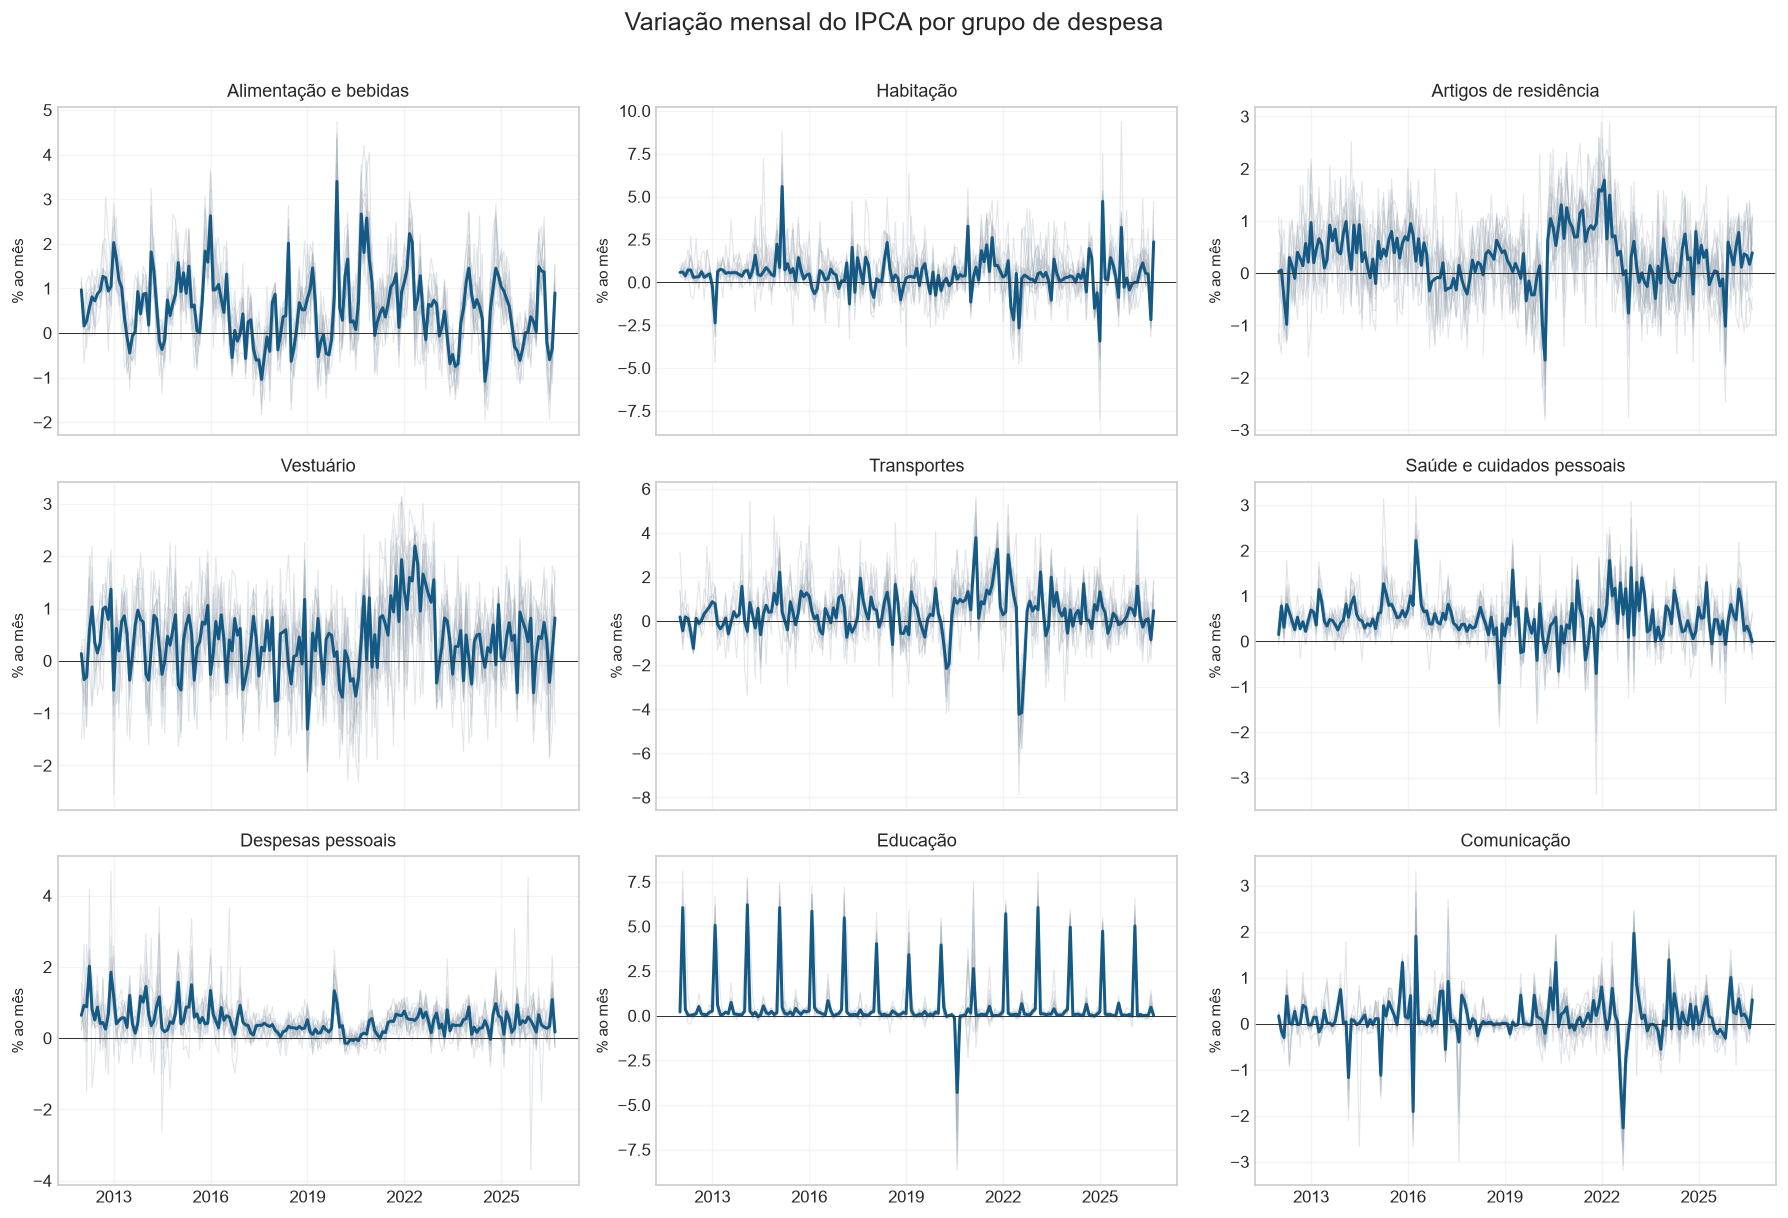

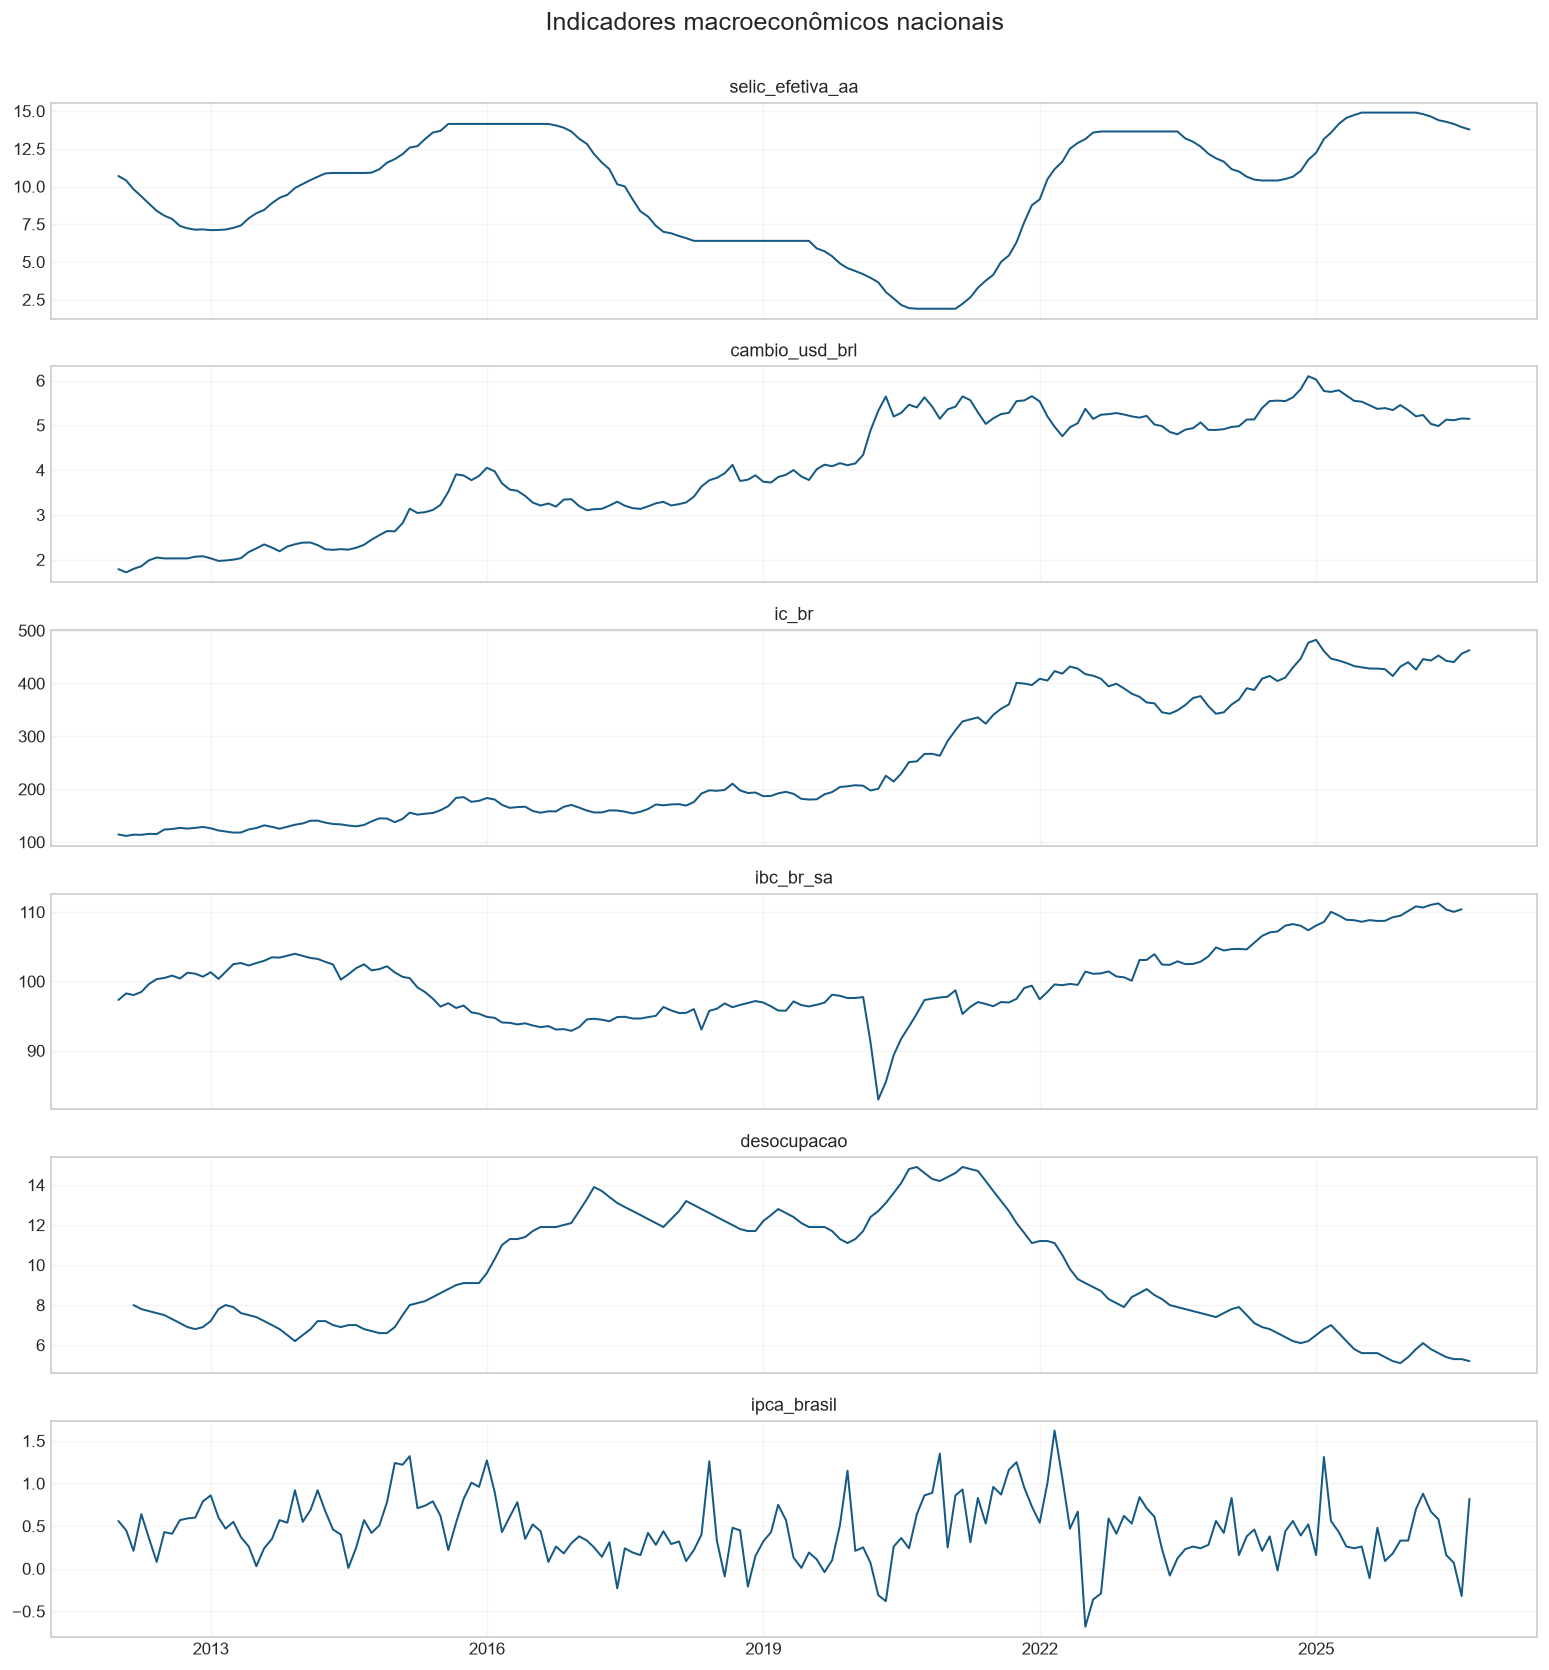

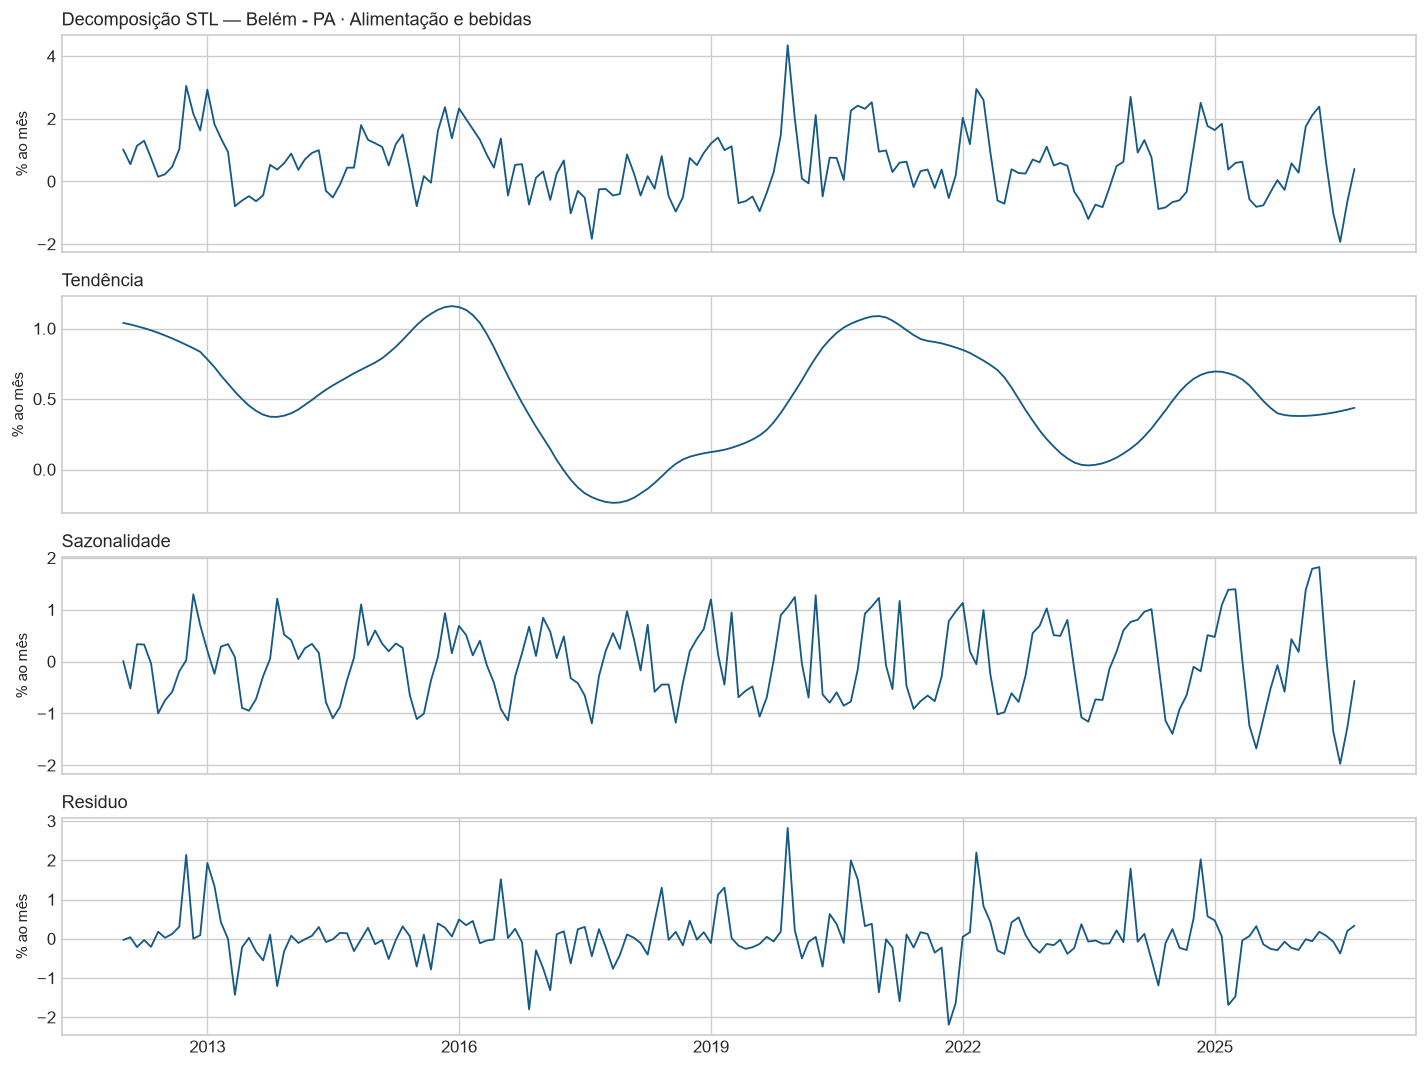

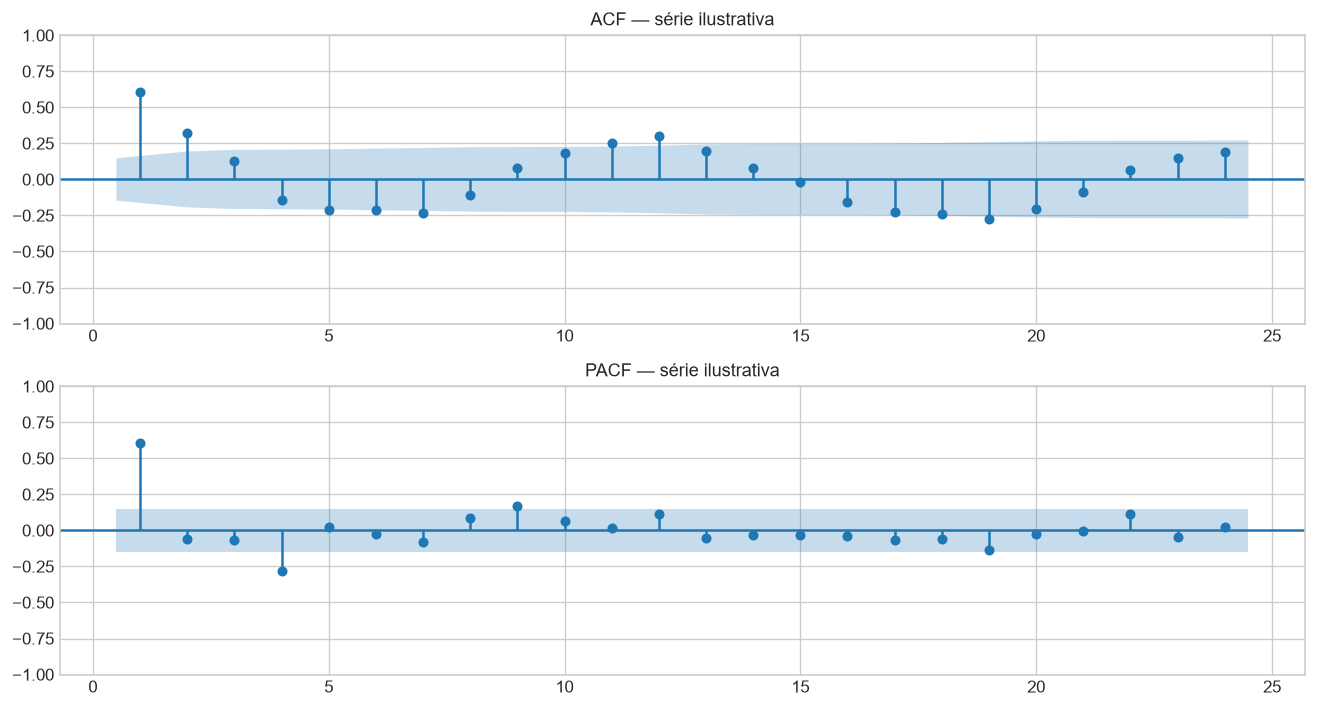

In [8]:
grupos = dados[["grupo_id", "grupo_despesa"]].drop_duplicates().sort_values("grupo_id")
fig, eixos = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for eixo, (_, info) in zip(eixos.flat, grupos.iterrows()):
    dados_grupo = dados.loc[dados["grupo_id"] == info["grupo_id"]]
    for _, serie in dados_grupo.groupby("area_id"):
        eixo.plot(serie["data"], serie[ALVO], color="#9aa6b2", alpha=0.28, linewidth=0.65)
    mediana = dados_grupo.groupby("data")[ALVO].median()
    eixo.plot(mediana.index, mediana.values, color="#155a85", linewidth=1.8)
    eixo.axhline(0, color="#333333", linewidth=0.6)
    eixo.set_title(info["grupo_despesa"])
    eixo.set_ylabel("% ao mês")
    eixo.xaxis.set_major_locator(mdates.YearLocator(3))
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eixo.grid(alpha=0.2)
fig.suptitle("Variação mensal do IPCA por grupo de despesa", fontsize=15, y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)

variaveis_macro = [
    coluna for coluna in dados.select_dtypes(include="number").columns
    if coluna not in {ALVO, "area_id", "grupo_id", "tabela_sidra"}
]
if variaveis_macro:
    fig, eixos = plt.subplots(len(variaveis_macro), 1, figsize=(13, 2.3 * len(variaveis_macro)), sharex=True)
    eixos = np.atleast_1d(eixos)
    serie_macro = dados[["data"] + variaveis_macro].drop_duplicates("data").sort_values("data")
    for eixo, variavel in zip(eixos, variaveis_macro):
        eixo.plot(serie_macro["data"], serie_macro[variavel], color="#155a85", linewidth=1.2)
        eixo.set_title(variavel)
        eixo.grid(alpha=0.2)
    eixos[-1].xaxis.set_major_locator(mdates.YearLocator(3))
    eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.suptitle("Indicadores macroeconômicos nacionais", fontsize=15, y=1.005)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

if not componentes_stl.empty:
    exemplo = resumo_stl.loc[resumo_stl["status"] == "ok"].sort_values("n_observacoes", ascending=False).iloc[0]
    serie_exemplo = componentes_stl
    for coluna in CHAVES:
        serie_exemplo = serie_exemplo.loc[serie_exemplo[coluna] == exemplo[coluna]]
    serie_exemplo = serie_exemplo.sort_values("data")

    fig, eixos = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for eixo, coluna, titulo in zip(
        eixos,
        ["observado", "tendencia", "sazonalidade", "residuo"],
        ["IPCA observado", "Tendência", "Sazonalidade", "Residuo"],
    ):
        eixo.plot(serie_exemplo["data"], serie_exemplo[coluna], color="#155a85", linewidth=1.1)
        eixo.set_ylabel("% ao mês")
        eixo.set_title(titulo, loc="left")
    eixos[0].set_title(f"Decomposição STL — {exemplo['area']} · {exemplo['grupo_despesa']}", loc="left")
    eixos[-1].xaxis.set_major_locator(mdates.YearLocator(3))
    eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    valores_exemplo = serie_exemplo["observado"].to_numpy()
    lags = min(24, len(valores_exemplo) // 2 - 1)
    if lags >= 1:
        fig, eixos = plt.subplots(2, 1, figsize=(11, 6))
        plot_acf(valores_exemplo, lags=lags, zero=False, ax=eixos[0])
        plot_pacf(valores_exemplo, lags=lags, zero=False, method="ywm", ax=eixos[1])
        eixos[0].set_title("ACF — série ilustrativa")
        eixos[1].set_title("PACF — série ilustrativa")
        fig.tight_layout()
        plt.show()
        plt.close(fig)
else:
    print("Não há séries com comprimento suficiente para a decomposicao STL.")

## 4. Leitura dos resultados

As tabelas acima resumem cobertura e estatísticas por grupo, valores ausentes, sinalizações IQR e diagnósticos de estacionariedade e sazonalidade. A interpretação deve considerar que:

- A mediana entre áreas facilita a visualização, mas não substitui a análise de cada série.
- ADF e KPSS partem de hipóteses nulas opostas; resultados divergentes pedem investigação adicional.
- Lacunas e observações iniciais indisponíveis podem limitar comparações temporais entre áreas. Nenhuma lacuna foi imputada.
- Sinalização IQR não implica erro: variações extremas podem refletir eventos econômicos reais e foram mantidas.

Os resultados numéricos são recalculados ao executar o notebook e acompanham a versão efetiva do arquivo de dados.

## Fontes, conteúdo da base e limitações

- **IPCA:** IBGE/SIDRA, tabelas [1419](https://sidra.ibge.gov.br/tabela/1419) e [7060](https://sidra.ibge.gov.br/tabela/7060), variação mensal por área e grupo de despesa.
- **Variáveis macroeconômicas:** Banco Central do Brasil, séries SGS 4189 (Selic), 3697 (câmbio), 27574 (IC-Br), 24364 (IBC-Br dessazonalizado), 24369 (desocupação) e 433 (IPCA Brasil).
- O arquivo analisado é o painel integrado `painel_ipca_macro.csv`; a cobertura e o período final dependem da versão da base compartilhada.
- Expectativas Focus e sentimento de atas/notícias não estão incluídos neste painel e, portanto, não são analisados aqui.
- Esta etapa é descritiva. Associações e diagnósticos de estacionariedade não demonstram causalidade nem desempenho preditivo.